# Longitudinal Topology, Structural Roles, and Null Models in Co-Authorship Networks
**Dataset:** C3L Lab / Adelaide University Bibliometric Corpus (`cleaned_aurora_data.csv`)

This notebook extends our co-authorship mapping into three structural analyses:
1. **Temporal Percolation (2021–2026):** Comparing cumulative network growth against a 3-year sliding window to track Giant Connected Component (GCC) consolidation and triadic closure.
2. **Structural Equivalence Across Disciplines:** Grouping researchers by 5-dimensional topological role signatures (rather than direct co-authorship) and measuring role divergence across Scimago Research Areas.
3. **Random Graph Null Models (CM vs. SBM):** Benchmarking the empirical network against Degree-Preserving Configuration Models and Stochastic Block Models to test whether clustering and departmental homophily are explained by degree sequences or block affinities.

In [14]:
import ast
import itertools
import re
import warnings
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import networkx as nx
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import jensenshannon
from scipy.stats import wasserstein_distance

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "axes.grid": True, "grid.alpha": 0.4})

# Load cleaned C3L publication data
df = pd.read_csv("cleaned_aurora_data.csv")
df["author_list"] = df["author_list"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
df["Pub_Year"] = df["Publication-Year"].astype(int)

def clean_quartile(q_val):
    q_str = str(q_val).upper().strip()
    return q_str if q_str in ["Q1", "Q2", "Q3", "Q4"] else "Unranked"

def parse_semicolon_list(val):
    if pd.isna(val):
        return []
    return list(set(re.sub(r"\s*\([Q0-9]+\)$", "", item).strip() for item in str(val).split(";") if item.strip()))

df["Clean_Quartile"] = df["SJR Best Quartile"].apply(clean_quartile)
df["Area_List"] = df["Areas"].apply(parse_semicolon_list)
df["Category_List"] = df["Categories"].apply(parse_semicolon_list)

print(f"Loaded {len(df)} unique publications ({df['Pub_Year'].min()}–{df['Pub_Year'].max()}).")

Loaded 2310 unique publications (2021–2026).


## 1. Longitudinal Slicing & Temporal Network Evolution

Each paper $p$ published in year $t$ forms a co-authorship clique among its authors. We compare two temporal regimes:
* **Cumulative graphs ($G_{\le t}$):** Retains all collaborations up to year $t$.
* **3-Year rolling windows ($G_{[t-2, t]}$):** Captures active collaborative turnover.

For each snapshot, we record the Giant Connected Component fraction $S(t) = |V_{\text{GCC}}| / |V_t|$, global transitivity $C(t) = \frac{3 N_{\triangle}}{N_{\wedge}}$, degree assortativity $r(t)$, and average shortest path length $\langle \ell(t) \rangle$ on the GCC (estimated via 250 random BFS source nodes for speed).

,Snapshot,Regime,Nodes,Edges,GCC_Ratio,Transitivity,Assortativity,Mean_Path_GCC,Year_End
0,2021,Cumulative (≤ Year),1459,4650,0.471556,0.658348,0.061638,5.385112,2021
1,2019–2021,3-Yr Rolling Window,1459,4650,0.471556,0.658348,0.061638,5.385112,2021
2,2022,Cumulative (≤ Year),2510,9109,0.674900,0.531615,-0.014773,6.145134,2022
3,2020–2022,3-Yr Rolling Window,2510,9109,0.674900,0.531615,-0.014773,6.145134,2022
4,2023,Cumulative (≤ Year),3316,12735,0.807901,0.459151,-0.040681,5.843697,2023
5,2021–2023,3-Yr Rolling Window,3316,12735,0.807901,0.459151,-0.040681,5.843697,2023
6,2024,Cumulative (≤ Year),4300,17672,0.906977,0.405948,-0.053005,5.518937,2024
7,2022–2024,3-Yr Rolling Window,3486,14071,0.909352,0.446940,-0.052578,5.804003,2024
8,2025,Cumulative (≤ Year),5161,22155,0.929277,0.372561,-0.049854,5.160309,2025
9,2023–2025,3-Yr Rolling Window,3643,14713,0.907219,0.443809,-0.045333,5.561139,2025


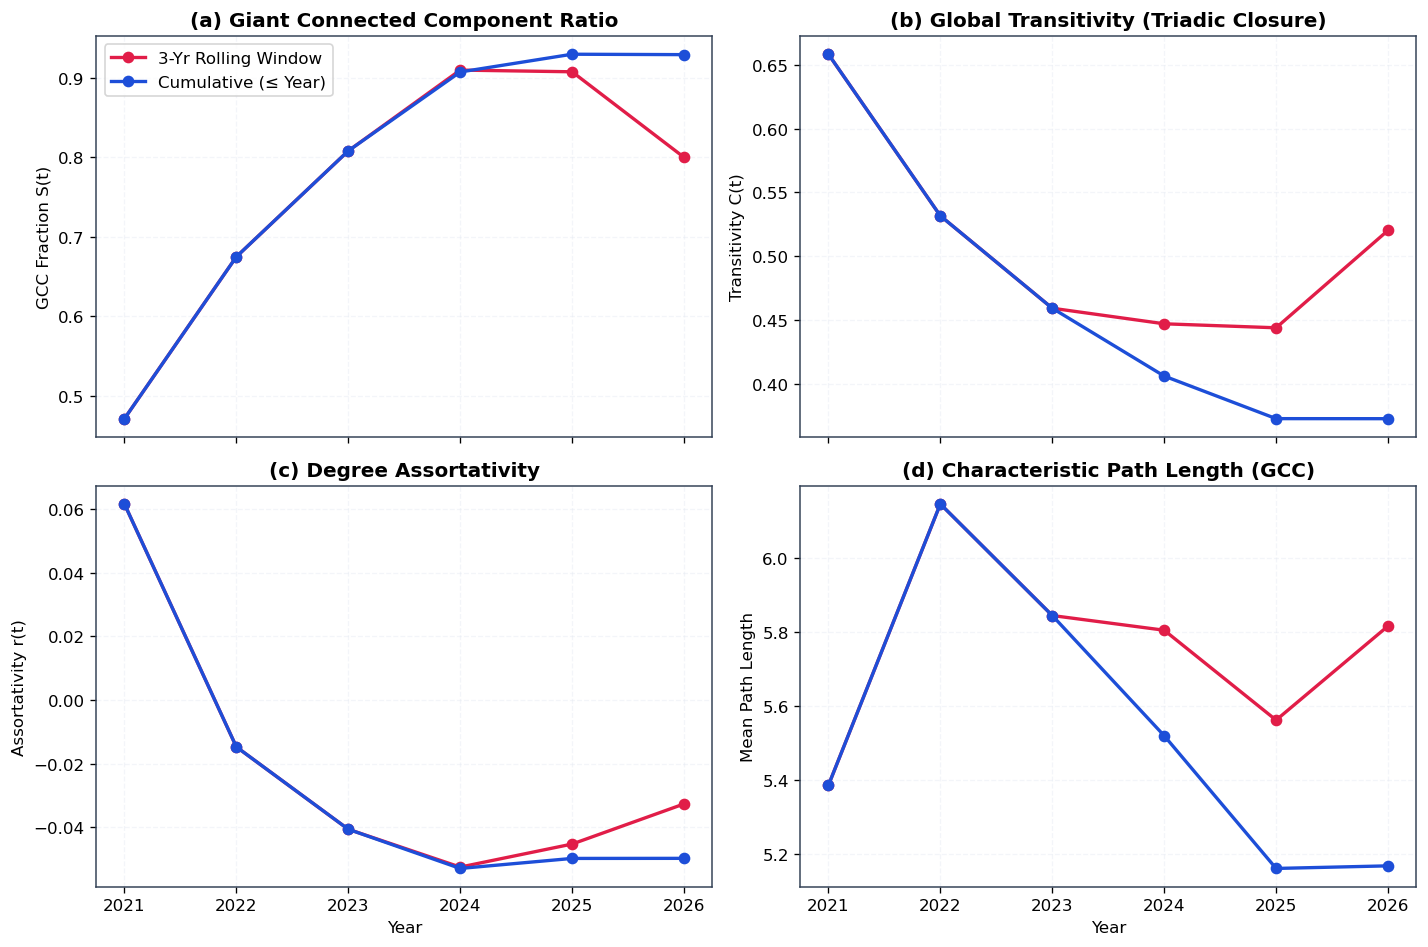

In [15]:
def build_coauthorship_graph(df_sub):
    edges = Counter()
    for authors in df_sub["author_list"]:
        clean_a = sorted(set(str(a).replace("\u2010", "-").strip() for a in authors if str(a).strip()))
        if len(clean_a) > 1:
            edges.update(itertools.combinations(clean_a, 2))
    G = nx.Graph()
    for (u, v), w in edges.items():
        G.add_edge(u, v, weight=float(w))
    return G

def get_snapshot_stats(G, label, regime, n_samples=250):
    n_nodes, n_edges = G.number_of_nodes(), G.number_of_edges()
    if n_nodes < 3:
        return None
    
    gcc_nodes = max(nx.connected_components(G), key=len)
    G_gcc = G.subgraph(gcc_nodes)
    
    # Sampled BFS shortest paths on the GCC
    rng = np.random.default_rng(42)
    sources = rng.choice(list(gcc_nodes), size=min(n_samples, len(gcc_nodes)), replace=False)
    dists = [d for s in sources for t, d in nx.single_source_shortest_path_length(G_gcc, s).items() if t != s]
    
    return {
        "Snapshot": label,
        "Regime": regime,
        "Nodes": n_nodes,
        "Edges": n_edges,
        "GCC_Ratio": len(gcc_nodes) / n_nodes,
        "Transitivity": nx.transitivity(G),
        "Assortativity": nx.degree_assortativity_coefficient(G),
        "Mean_Path_GCC": float(np.mean(dists))
    }

years = sorted(df["Pub_Year"].unique())
records = []

for yr in years:
    res_cum = get_snapshot_stats(build_coauthorship_graph(df[df["Pub_Year"] <= yr]), str(yr), "Cumulative (≤ Year)")
    res_cum["Year_End"] = yr
    records.append(res_cum)
    
    df_win = df[(df["Pub_Year"] >= yr - 2) & (df["Pub_Year"] <= yr)]
    res_win = get_snapshot_stats(build_coauthorship_graph(df_win), f"{yr-2}–{yr}", "3-Yr Rolling Window")
    res_win["Year_End"] = yr
    records.append(res_win)

temporal_df = pd.DataFrame(records)
display(temporal_df)

# Plot Temporal Evolution
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
colors = {"Cumulative (≤ Year)": "#1d4ed8", "3-Yr Rolling Window": "#e11d48"}

plot_specs = [
    ("GCC_Ratio", "GCC Fraction S(t)", "(a) Giant Connected Component Ratio", axes[0, 0]),
    ("Transitivity", "Transitivity C(t)", "(b) Global Transitivity (Triadic Closure)", axes[0, 1]),
    ("Assortativity", "Assortativity r(t)", "(c) Degree Assortativity", axes[1, 0]),
    ("Mean_Path_GCC", "Mean Path Length", "(d) Characteristic Path Length (GCC)", axes[1, 1])
]

for col, ylabel, title, ax in plot_specs:
    for regime, grp in temporal_df.groupby("Regime"):
        ax.plot(grp["Year_End"], grp[col], marker="o", linewidth=2, color=colors[regime], label=regime)
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel(ylabel)

axes[0, 0].legend()
axes[1, 0].set_xlabel("Year")
axes[1, 1].set_xlabel("Year")
plt.tight_layout()
plt.savefig("Fig1_Temporal_Evolution.png", bbox_inches="tight")
plt.show()

## 2. Structural Equivalence & Cross-Discipline Role Comparison

To identify researchers who play equivalent structural roles across disconnected disciplines, we represent each node $i \in V$ using a 5-feature structural signature:
1. **Log Degree ($\ln(k_i + 1)$):** Local collaboration volume.
2. **Local Clustering ($C_i$):** Fraction of closed triangles among $i$'s co-authors.
3. **$k$-Core Shell ($c_i$):** Coreness depth under iterative degree decomposition.
4. **Log PageRank:** Global centrality in the weighted co-authorship graph.
5. **Category Diversity ($P_i$):** Participation index across the 239 Scimago categories, $P_i = 1 - \sum_{s} (\kappa_{is} / \kappa_i)^2$, where $P_i = 0$ indicates a single-category specialist and $P_i \to 1$ indicates a broad interdisciplinary researcher.

We standardize the feature matrix and apply Ward hierarchical clustering ($K = 4$ role classes). We then compare role distributions across Broad Research Areas using Jensen–Shannon divergence ($D_{\text{JS}}$) and compare Q1 vs. Q2–Q4 participation using the 1-Wasserstein distance ($W_1$).

Full Network: 5165 authors, 22165 edges.
Wasserstein Distance (Category Diversity, Q1 vs. Q2-Q4): W1 = 0.1193


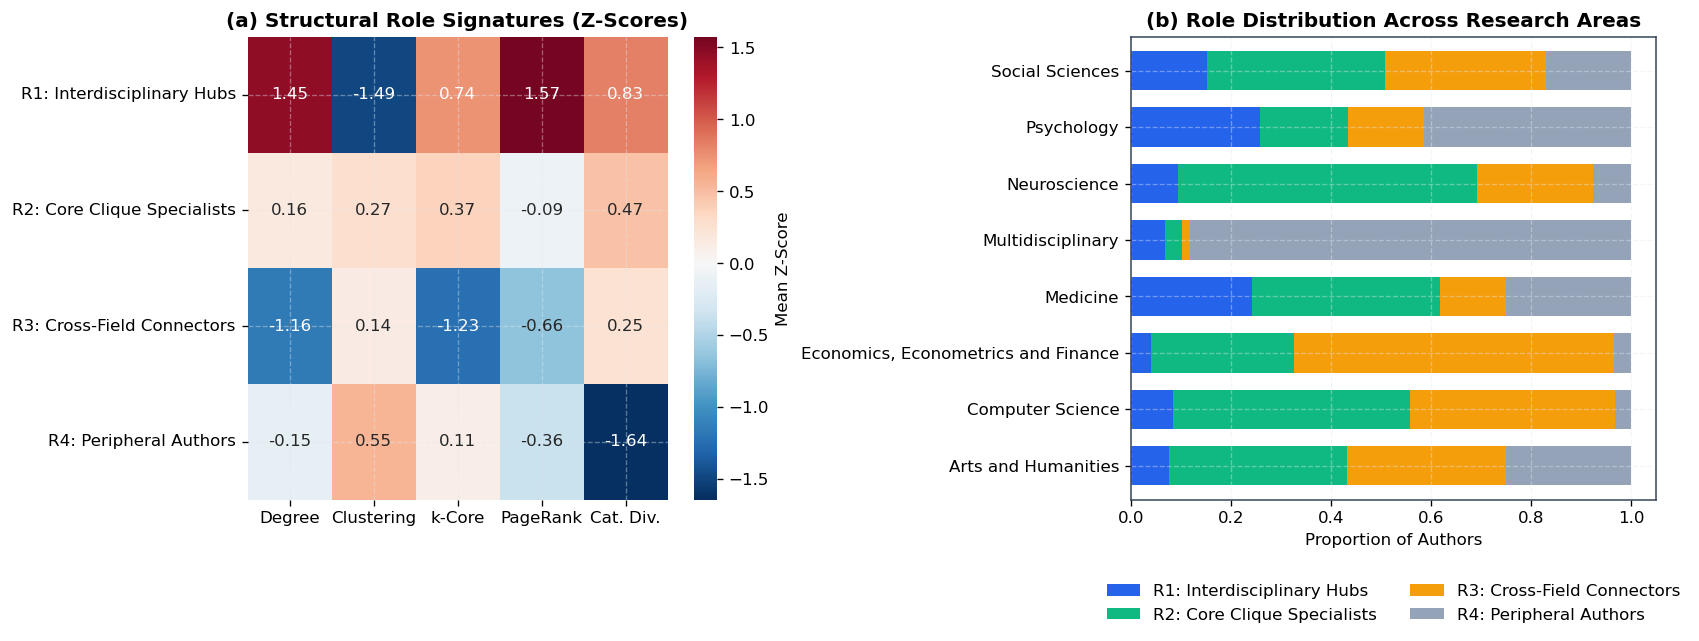

In [16]:
G_full = build_coauthorship_graph(df)
G_full.remove_edges_from(nx.selfloop_edges(G_full))
print(f"Full Network: {G_full.number_of_nodes()} authors, {G_full.number_of_edges()} edges.")

# Track category and research area counts per author
author_cats = defaultdict(Counter)
author_areas = defaultdict(Counter)
author_quarts = defaultdict(Counter)

for _, row in df.iterrows():
    authors = [str(a).replace("\u2010", "-").strip() for a in row["author_list"] if str(a).strip()]
    for a in authors:
        for c in row["Category_List"]:
            author_cats[a][c] += 1
        for ar in row["Area_List"]:
            author_areas[a][ar] += 1
        author_quarts[a][row["Clean_Quartile"]] += 1

# Compute the 5 core structural features
degrees = dict(G_full.degree())
clustering = nx.clustering(G_full)
k_cores = nx.core_number(G_full)
pagerank = nx.pagerank(G_full, weight="weight")
N_total = G_full.number_of_nodes()

rows = []
for n in G_full.nodes():
    tot_c = sum(author_cats[n].values())
    cat_div = 1.0 - sum((cnt / tot_c) ** 2 for cnt in author_cats[n].values()) if tot_c > 0 else 0.0
    
    main_area = author_areas[n].most_common(1)[0][0] if author_areas[n] else "Unassigned"
    q1_cnt = author_quarts[n]["Q1"]
    other_q = author_quarts[n]["Q2"] + author_quarts[n]["Q3"] + author_quarts[n]["Q4"]
    q_group = "Q1-Dominant" if (q1_cnt >= other_q and q1_cnt > 0) else "Q2–Q4 / Mixed"
    
    rows.append({
        "Author": n,
        "Primary_Area": main_area,
        "Quality_Tier": q_group,
        "Log_Degree": np.log1p(degrees[n]),
        "Clustering": clustering[n],
        "K_Core": float(k_cores[n]),
        "Log_PageRank": np.log1p(N_total * pagerank[n]),
        "Category_Diversity": cat_div
    })

role_df = pd.DataFrame(rows)
feat_cols = ["Log_Degree", "Clustering", "K_Core", "Log_PageRank", "Category_Diversity"]

# Standardize features (z-scores) and run Ward hierarchical clustering
X = role_df[feat_cols].values
X_std = (X - X.mean(axis=0)) / X.std(axis=0)
role_df["Cluster_ID"] = fcluster(linkage(X_std, method="ward"), t=4, criterion="maxclust")

# Label the 4 clusters based on their average feature profiles
means = role_df.groupby("Cluster_ID")[feat_cols].mean()
rem = list(means.index)
label_map = {}

c_hub = means.loc[rem].eval("Log_Degree + Log_PageRank + Category_Diversity").idxmax()
label_map[c_hub] = "R1: Interdisciplinary Hubs"
rem.remove(c_hub)

c_clique = means.loc[rem].eval("K_Core + Clustering").idxmax()
label_map[c_clique] = "R2: Core Clique Specialists"
rem.remove(c_clique)

c_bridge = means.loc[rem]["Category_Diversity"].idxmax()
label_map[c_bridge] = "R3: Cross-Field Connectors"
rem.remove(c_bridge)

label_map[rem[0]] = "R4: Peripheral Authors"

role_df["Role"] = role_df["Cluster_ID"].map(label_map)
role_order = sorted(label_map.values())

# Compare Q1 vs Q2-Q4 Category Diversity using 1-Wasserstein Distance
w1_dist = wasserstein_distance(
    role_df[role_df["Quality_Tier"] == "Q1-Dominant"]["Category_Diversity"],
    role_df[role_df["Quality_Tier"] == "Q2–Q4 / Mixed"]["Category_Diversity"]
)
print(f"Wasserstein Distance (Category Diversity, Q1 vs. Q2-Q4): W1 = {w1_dist:.4f}")

# Compare Role Distributions across Top 8 Research Areas
top_areas = [a for a, c in role_df["Primary_Area"].value_counts().items() if a != "Unassigned" and c >= 30][:8]
area_dist = pd.crosstab(
    role_df[role_df["Primary_Area"].isin(top_areas)]["Primary_Area"],
    role_df[role_df["Primary_Area"].isin(top_areas)]["Role"],
    normalize="index"
).reindex(columns=role_order, fill_value=0.0)

# Clean 2-Panel Plot (No Overlapping Text)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

z_df = pd.DataFrame(X_std, columns=["Degree", "Clustering", "k-Core", "PageRank", "Cat. Div."])
z_means = z_df.groupby(role_df["Role"]).mean().reindex(role_order)
sns.heatmap(z_means, ax=ax1, cmap="RdBu_r", center=0, annot=True, fmt=".2f", cbar_kws={"label": "Mean Z-Score"})
ax1.set_title("(a) Structural Role Signatures (Z-Scores)", fontweight="bold")
ax1.set_ylabel("")

area_dist.plot(kind="barh", stacked=True, ax=ax2, color=["#2563eb", "#10b981", "#f59e0b", "#94a3b8"], width=0.7)
ax2.set_title("(b) Role Distribution Across Research Areas", fontweight="bold")
ax2.set_xlabel("Proportion of Authors")
ax2.set_ylabel("")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)

plt.tight_layout()
plt.savefig("Fig2_Structural_Roles.png", bbox_inches="tight")
plt.show()

## 3. Random Graph Null Models: Configuration Model vs. Stochastic Block Model

The empirical GCC exhibits high transitivity ($C_{\text{obs}} = 0.363$) and strong Research-Area homophily ($r_{\text{Area}} = 0.610$). To test whether these properties arise simply from degree heterogeneity or departmental group sizes, we compare $G_{\text{obs}}$ against $M = 30$ realizations of two null models:
1. **Configuration Model ($\mathcal{G}_{\text{CM}}$):** Preserves the exact degree sequence $(k_1, \dots, k_N)$ while randomizing connections.
2. **Stochastic Block Model ($\mathcal{G}_{\text{SBM}}$):** Assigns nodes to Research Area blocks and generates edges with empirical block probabilities $\hat{\Omega}_{rs} = e_{rs} / (n_r n_s)$ (or $2e_{rr}/n_r(n_r-1)$ within blocks).

,Metric,Empirical,CM_Mean±SD,Z_CM,SBM_Mean±SD,Z_SBM
0,Global Transitivity (C),0.3627,0.0070 ± 0.0003,1127.83,0.0040 ± 0.0002,1566.85
1,Mean Local Clustering,0.8449,0.0072 ± 0.0005,1812.40,0.0042 ± 0.0003,3122.27
2,Area Homophily (Assortativity),0.6096,-0.0004 ± 0.0039,158.12,0.6099 ± 0.0049,-0.06
3,Inter-Area Edge Fraction,0.2733,0.7007 ± 0.0027,-158.43,0.2730 ± 0.0034,0.08


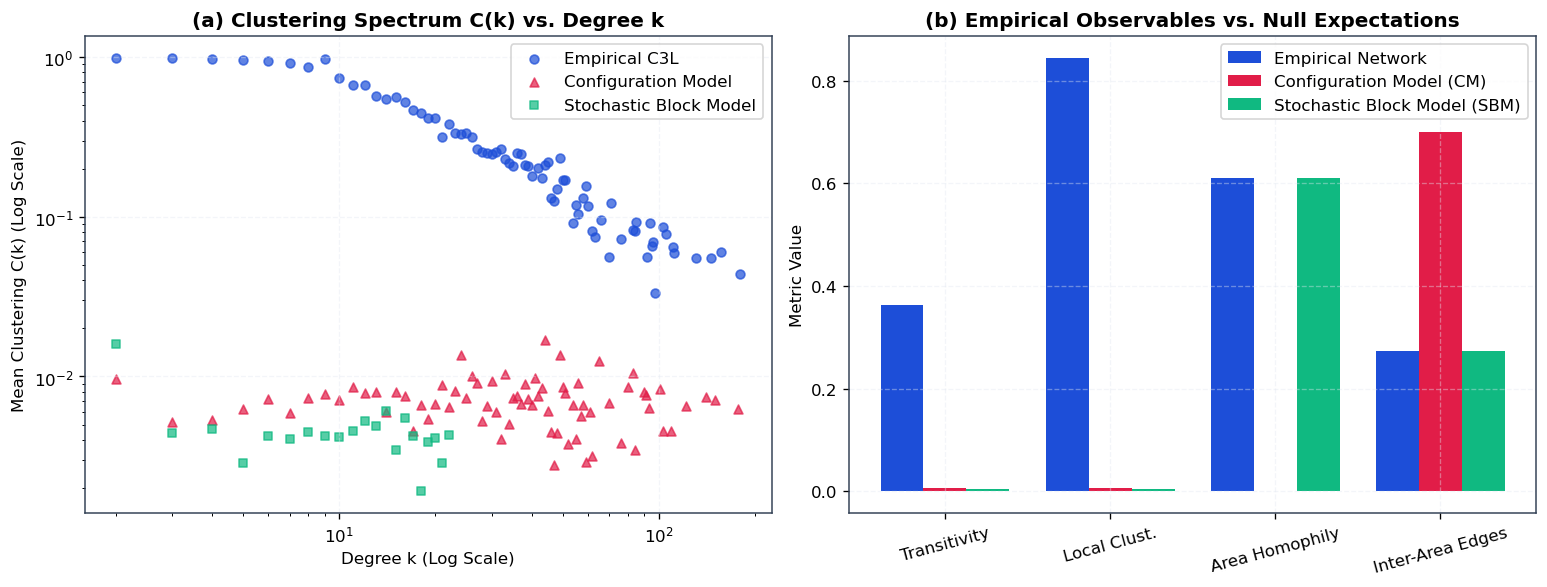

In [18]:
gcc_nodes = max(nx.connected_components(G_full), key=len)
G_emp = nx.Graph(G_full.subgraph(gcc_nodes))
G_emp.remove_edges_from(nx.selfloop_edges(G_emp))

# Group nodes into top 7 Research Area blocks + "Other Areas"
area_counts = Counter( dict(zip(role_df["Author"], role_df["Primary_Area"]))[n] for n in G_emp.nodes() )
top_blocks = [ar for ar, _ in area_counts.most_common(7) if ar != "Unassigned"]
author_to_area = dict(zip(role_df["Author"], role_df["Primary_Area"]))

node_block = {n: (author_to_area[n] if author_to_area[n] in top_blocks else "Other Areas") for n in G_emp.nodes()}
nx.set_node_attributes(G_emp, node_block, "block")

blocks = sorted(set(node_block.values()))
b_idx = {b: i for i, b in enumerate(blocks)}
block_lists = [[n for n in G_emp.nodes() if node_block[n] == b] for b in blocks]
sizes = [len(lst) for lst in block_lists]

# Estimate SBM block probability matrix \hat{\Omega}
B = len(blocks)
edge_counts = np.zeros((B, B))
for u, v in G_emp.edges():
    bu, bv = b_idx[node_block[u]], b_idx[node_block[v]]
    edge_counts[bu, bv] += 1.0
    if bu != bv:
        edge_counts[bv, bu] += 1.0

omega = np.zeros((B, B))
for r in range(B):
    for s in range(B):
        denom = sizes[r] * (sizes[r] - 1) / 2.0 if r == s else sizes[r] * sizes[s]
        omega[r, s] = edge_counts[r, s] / max(1.0, denom)

def get_observables(G_in):
    trans = nx.transitivity(G_in)
    clust = nx.average_clustering(G_in)
    assort = nx.attribute_assortativity_coefficient(G_in, "block")
    inter = sum(1 for u, v in G_in.edges() if G_in.nodes[u]["block"] != G_in.nodes[v]["block"]) / G_in.number_of_edges()
    return trans, clust, assort, inter

obs_vals = get_observables(G_emp)
deg_seq = [d for _, d in G_emp.degree()]
nodes_list = list(G_emp.nodes())

# Simulate 30 Configuration Model and SBM graphs
M = 30
cm_runs, sbm_runs = [], []

for m in range(M):
    G_cm = nx.Graph(nx.configuration_model(deg_seq, seed=100 + m))
    G_cm.remove_edges_from(nx.selfloop_edges(G_cm))
    for i, u in enumerate(nodes_list):
        G_cm.nodes[i]["block"] = node_block[u]
    cm_runs.append(get_observables(G_cm))
    
    G_sbm = nx.stochastic_block_model(sizes, omega, seed=500 + m)
    for i, data in G_sbm.nodes(data=True):
        data["block"] = blocks[data["block"]]
    sbm_runs.append(get_observables(G_sbm))

cm_arr, sbm_arr = np.array(cm_runs), np.array(sbm_runs)
names = ["Global Transitivity (C)", "Mean Local Clustering", "Area Homophily (Assortativity)", "Inter-Area Edge Fraction"]

summary = []
for i, name in enumerate(names):
    cm_m, cm_s = cm_arr[:, i].mean(), max(1e-6, cm_arr[:, i].std())
    sbm_m, sbm_s = sbm_arr[:, i].mean(), max(1e-6, sbm_arr[:, i].std())
    summary.append({
        "Metric": name,
        "Empirical": round(obs_vals[i], 4),
        "CM_Mean±SD": f"{cm_m:.4f} ± {cm_s:.4f}",
        "Z_CM": round((obs_vals[i] - cm_m) / cm_s, 2),
        "SBM_Mean±SD": f"{sbm_m:.4f} ± {sbm_s:.4f}",
        "Z_SBM": round((obs_vals[i] - sbm_m) / sbm_s, 2)
    })

summary_df = pd.DataFrame(summary)
display(summary_df)

# Plot Empirical vs Null Models (2-Panel Clean Layout)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Panel (a): Degree-clustering curve C(k)
for G_plot, lbl, col, mk in [(G_emp, "Empirical C3L", "#1d4ed8", "o"), (G_cm, "Configuration Model", "#e11d48", "^"), (G_sbm, "Stochastic Block Model", "#10b981", "s")]:
    ck_df = pd.DataFrame({"k": dict(G_plot.degree()).values(), "c": nx.clustering(G_plot).values()})
    ck_curve = ck_df[ck_df["k"] >= 2].groupby("k")["c"].mean()
    ax1.scatter(ck_curve.index, ck_curve.values, color=col, marker=mk, alpha=0.7, s=28, label=lbl)

ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_title("(a) Clustering Spectrum C(k) vs. Degree k", fontweight="bold")
ax1.set_xlabel("Degree k (Log Scale)")
ax1.set_ylabel("Mean Clustering C(k) (Log Scale)")
ax1.legend()

# Panel (b): Direct Bar Comparison of Empirical vs CM vs SBM
x_pos = np.arange(len(names))
w = 0.26
ax2.bar(x_pos - w, obs_vals, width=w, color="#1d4ed8", label="Empirical Network")
ax2.bar(x_pos, cm_arr.mean(axis=0), width=w, color="#e11d48", label="Configuration Model (CM)")
ax2.bar(x_pos + w, sbm_arr.mean(axis=0), width=w, color="#10b981", label="Stochastic Block Model (SBM)")
ax2.set_xticks(x_pos)
ax2.set_xticklabels(["Transitivity", "Local Clust.", "Area Homophily", "Inter-Area Edges"], rotation=15)
ax2.set_title("(b) Empirical Observables vs. Null Expectations", fontweight="bold")
ax2.set_ylabel("Metric Value")
ax2.legend()

plt.tight_layout()
plt.savefig("Fig3_Null_Model_Benchmark.png", bbox_inches="tight")
plt.show()